> Catatan: output yang tersimpan di notebook ini berasal dari run eksperimen sebelumnya. Model final yang dipakai aplikasi ada di `models-balanced/`. Lihat `README.md` untuk angka dan keterbatasan.

## 1. Importing Libraries

First, we import all the necessary libraries required for data processing, feature engineering, visualization, and model training.

In [17]:
import csv
import itertools
import numpy as np
import os
import re
import string
import hashlib
from urllib.parse import urlparse, parse_qs, urlsplit

import pandas as pd
from joblib import dump, load
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import LabelEncoder

import tldextract
# from googlesearch import search  # Uncomment if needed

import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

from sklearn import metrics
from xgboost import XGBClassifier
from imblearn.over_sampling import RandomOverSampler

import ipaddress

# Set plot style for better aesthetics
sns.set(style="whitegrid")

## 2. Configuration

Set up the configuration, including the path to your dataset. Ensure you replace `'./balanced_urls.csv'` dengan path sebenarnya ke file CSV Anda yang berisi data URL.

In [18]:
# Path to your dataset CSV file
DATA_PATH = './balanced_urls.csv'

# Path to save models and encoders
MODEL_PATH = './models-balanced/final_xgb_model.pkl'
ENCODER_PATH = './models-balanced/target_encoder.pkl'
LABEL_ENCODER_PATH = './models-balanced/label_encoder.pkl'

## 3. Feature Engineering Functions

Define a series of functions to extract meaningful features from URLs. These features will help the model distinguish between malicious and benign URLs.

In [19]:
# Daftar TLD terpercaya
from constant_datas import TRUSTED_TLDS

In [20]:
from constant_datas import TRUSTED_TLDS
import re
import tldextract
from urllib.parse import urlparse, parse_qs
import numpy as np

# 1. HTTPS detection


def secure_http(url):
    """Check if the URL uses HTTPS."""
    try:
        return 1 if url.lower().startswith('https://') else 0
    except Exception as e:
        print(f"Error in secure_http: {e}")
        return 0

# 2. URL Length


def url_length(url):
    """Calculate the length of the URL excluding the scheme."""
    try:
        stripped_url = re.sub(r'^https?://', '', url)
        return len(stripped_url)
    except Exception as e:
        print(f"Error in url_length: {e}")
        return 0

# 3. Long Subdomain Detection


def is_long_subdomain(url, threshold=20):
    """Check if the subdomain length exceeds a certain threshold."""
    try:
        subdomain = tldextract.extract(url).subdomain
        return 1 if len(subdomain) > threshold else 0
    except Exception as e:
        print(f"Error in is_long_subdomain: {e}")
        return 0

# 4. Domain Entropy


def domain_entropy(url):
    """Calculate entropy of the domain name."""
    try:
        ext = tldextract.extract(url)
        domain = ext.domain
        prob = [float(domain.count(c)) / len(domain) for c in set(domain)]
        return -sum([p * np.log2(p) for p in prob])
    except Exception as e:
        print(f"Error in domain_entropy: {e}")
        return 0

# 5. Protocol Count


def protocol_count(url):
    """Count the occurrences of protocols like 'http' or 'https'."""
    try:
        return url.lower().count('http')
    except Exception as e:
        print(f"Error in protocol_count: {e}")
        return 0

# 6. Suspicious Path Words


def suspicious_path_words(url):
    """Check for sensitive words in the URL path."""
    try:
        path = urlparse(url).path.lower()
        sensitive_terms = [
            "sales",
            "admin",
            "user",
            "verify",       # Mengelabui korban agar memverifikasi akun
            "secure",       # Berpura-pura menjamin keamanan
            "update",       # Menarik korban untuk memperbarui data
            "checkout",     # Menargetkan pembayaran palsu
            "password",     # Mencoba mendapatkan kata sandi korban
            "payment",      # Menargetkan pembayaran korban
            "signin",       # Halaman login palsu
            "reset",        # Mereset kata sandi palsu
            "support",      # Menarik korban dengan klaim layanan pelanggan
            "transfer",     # Menargetkan transaksi bank
            "validate",     # Meminta validasi data
            "submit",       # Halaman pengumpulan informasi
            "details",      # Meminta informasi pribadi
            "auth",         # Autentikasi palsu
            "confirm",      # Menipu pengguna untuk konfirmasi
            "free",         # Menarik dengan tawaran gratis
            "deal",         # Menarik dengan penawaran diskon
            "offer",        # Memancing pengguna dengan promosi
            "service",      # Mengelabui dengan klaim layanan resmi
            "tracking",     # Sering muncul dalam URL phishing pengiriman barang
            "id",           # Sering digunakan untuk meniru ID pengguna
            "dashboard",    # Menargetkan akun dashboard
            "security",     # Klaim keamanan palsu
            "invoice"       # Menargetkan korban dengan klaim tagihan palsu
        ]
        return 1 if any(term in path for term in sensitive_terms) else 0
    except Exception as e:
        print(f"Error in suspicious_path_words: {e}")
        return 0

# 7. TLD Reputation


def tld_reputation(url):
    """Assign a reputation score based on the TLD using TRUSTED_TLDS."""
    try:
        ext = tldextract.extract(url)
        tld = ext.suffix.lower()
        return 1 if tld in TRUSTED_TLDS else 0
    except Exception as e:
        print(f"Error in tld_reputation: {e}")
        return 0

# 8. Digit-to-Letter Ratio


def digit_letter_ratio(url):
    """Calculate the ratio of digits to letters in the URL."""
    try:
        digits = sum(1 for c in url if c.isdigit())
        letters = sum(1 for c in url if c.isalpha())
        return digits / letters if letters > 0 else 0
    except Exception as e:
        print(f"Error in digit_letter_ratio: {e}")
        return 0

# 9. Number of Special Characters


def special_char_count(url):
    """Count the number of special characters in the URL."""
    try:
        special_chars = sum(1 for c in url if not c.isalnum())
        return special_chars
    except Exception as e:
        print(f"Error in special_char_count: {e}")
        return 0

# 10. Path Length


def path_length(url):
    """Calculate the length of the path in the URL."""
    try:
        return len(urlparse(url).path)
    except Exception as e:
        print(f"Error in path_length: {e}")
        return 0

# 11. Presence of Cyrillic Characters


def contains_cyrillic(url):
    """Check if the URL contains Cyrillic characters."""
    try:
        return 1 if re.search('[\u0400-\u04FF]', url) else 0
    except Exception as e:
        print(f"Error in contains_cyrillic: {e}")
        return 0

# 12. Presence of '@' in URL


def contains_at_symbol(url):
    """Check if the URL contains '@'."""
    try:
        return 1 if '@' in url else 0
    except Exception as e:
        print(f"Error in contains_at_symbol: {e}")
        return 0

# 13. Number of Dots in Subdomain


def subdomain_dot_count(url):
    """Count the number of dots in the subdomain."""
    try:
        subdomain = tldextract.extract(url).subdomain
        return subdomain.count('.') if subdomain else 0
    except Exception as e:
        print(f"Error in subdomain_dot_count: {e}")
        return 0

# 14. Number of Query Parameters


def query_param_count(url):
    """Count the number of query parameters in the URL."""
    try:
        query = urlparse(url).query
        return len(parse_qs(query))
    except Exception as e:
        print(f"Error in query_param_count: {e}")
        return 0

# 15. Presence of Zeroes in Path


def path_zero_count(url):
    """Count the number of zeroes in the URL path."""
    try:
        path = urlparse(url).path
        return path.count('0')
    except Exception as e:
        print(f"Error in path_zero_count: {e}")
        return 0

# 16. Path Special Characters


def path_special_characters(url):
    """Count the number of special characters in the path."""
    try:
        path = urlparse(url).path
        special_chars = sum(1 for c in path if not c.isalnum())
        return special_chars
    except Exception as e:
        print(f"Error in path_special_characters: {e}")
        return 0

# 17. Number of Hyphens in Domain


def domain_hyphen_count(url):
    """Count the number of hyphens in the domain."""
    try:
        domain = tldextract.extract(url).domain
        return domain.count('-')
    except Exception as e:
        print(f"Error in domain_hyphen_count: {e}")
        return 0

# 18. Ratio of Uppercase to Lowercase Characters


def uppercase_lowercase_ratio(url):
    """Calculate the ratio of uppercase to lowercase characters in the URL."""
    try:
        uppercase = sum(1 for c in url if c.isupper())
        lowercase = sum(1 for c in url if c.islower())
        return uppercase / lowercase if lowercase > 0 else 0
    except Exception as e:
        print(f"Error in uppercase_lowercase_ratio: {e}")
        return 0

# 19. Length of the Primary Domain


def domain_length(url):
    """Calculate the length of the primary domain."""
    try:
        domain = tldextract.extract(url).domain
        return len(domain)
    except Exception as e:
        print(f"Error in domain_length: {e}")
        return 0

# 20. Query String Length


def query_string_length(url):
    """Calculate the length of the query string."""
    try:
        query = urlparse(url).query
        return len(query)
    except Exception as e:
        print(f"Error in query_string_length: {e}")
        return 0


# Feature list for integration into XGBoost or other ML models

# advanced_features = [
#     "secure_http",
#     "url_length",
#     "subdomain_length",
#     "domain_entropy",
#     "protocol_count",
#     "suspicious_path_words",
#     "tld_reputation",
#     "digit_letter_ratio",
#     "special_char_count",
#     "path_length",
#     "contains_cyrillic",
#     "contains_at_symbol",
#     "subdomain_dot_count",
#     "query_param_count",
#     "path_zero_count",
#     "path_special_characters",
#     "domain_hyphen_count",
#     "uppercase_lowercase_ratio",
#     "domain_length",
#     "query_string_length",
#     # "trusted_and_https",
#     # "entropy_special_char",
# ]

advanced_features = [
    'secure_http',  # 1
    'url_length',  # 2
    'domain_entropy',  # 3
    'contains_cyrillic',  # 4
    'special_char_count',  # 5
    'tld_reputation',  # 6
    'path_length',  # 7
    'digit_letter_ratio',  # 8
    'contains_at_symbol',  # 9
    'subdomain_dot_count',  # 10
    'query_param_count',  # 11
    'path_zero_count',  # 12
    'path_special_characters',  # 13
    'domain_hyphen_count',  # 14
    'uppercase_lowercase_ratio',  # 15
    'domain_length',  # 16
    'query_string_length',  # 17
    "protocol_count",  # 18
    "suspicious_path_words",  # 19
    "is_long_subdomain",  # 20


    # combination features
    # 'trusted_and_https',
    # 'entropy_special_char',
    # 'long_url_long_subdomain',
    # 'path_sensitive_score',
    # 'upper_lower_special_ratio',
    # 'query_complexity',
    # 'entropy_domain_length',
    # 'secure_path_score',
    # 'tld_upper_ratio'

    # 'suspicious_words', # 18
    # 'domain_token_count', # 19
    # 'subdomain_length' # 20
]


# 1. domain_entropy: 480.000
# 2. special_char_count: 419.625
# 3. url_length: 418.750
# 4. domain_length: 378.250
# 5. path_length: 327.750
# 6. path_special_characters: 305.625
# 7. digit_letter_ratio: 272.875
# 8. uppercase_lowercase_ratio: 176.500
# 9. query_string_length: 152.750
# 10. subdomain_dot_count: 115.125
# 11. domain_hyphen_count: 92.750
# 12. query_param_count: 92.125
# 13. secure_http: 83.000
# 14. tld_reputation: 77.250
# 15. suspicious_path_words: 67.625
# 16. is_long_subdomain: 60.250
# 17. contains_at_symbol: 53.875
# 18. path_zero_count: 48.375
# 19. protocol_count: 42.750
# 20. contains_cyrillic: 13.250

# masalah lexical featurenya dicek lagi, akurasi nya bagus tapi masih belum bagus dan cyrillic nya masih belum bagus

# ======================================
# 4. Loading the Dataset and Remove Duplicates Data
# ======================================

In [21]:
# Load Data
try:
    data = pd.read_csv(DATA_PATH)
    print(f"Dataset loaded successfully with shape: {data.shape}")
    
    # Remove duplicates
    data = data.drop_duplicates()
    print(f"Dataset shape after removing duplicates: {data.shape}")
except FileNotFoundError:
    print(f"Error: File not found at {DATA_PATH}. Please check the path.")
    exit(1)
except Exception as e:
    print(f"An error occurred while loading the data: {e}")
    exit(1)

Dataset loaded successfully with shape: (633021, 3)
Dataset shape after removing duplicates: (633011, 3)


# ======================================
# 5. Exploring the Dataset
# ======================================


Random rows of the dataset:
                                                                                                                                                                  url     label  result
                                                                                                      https://www.kauffman.org/about-foundation/kauffman-stadium.aspx    benign       0
                                                                                                                       https://www.rockhurstdining.com/locations.html    benign       0
                                                                                                                      https://www.4tube.com/pornstars/jessica-bangkok    benign       0
                                                                                                                   http://www.footwise.nl/images/stories/apsmk1.4.png malicious       1
                                                   

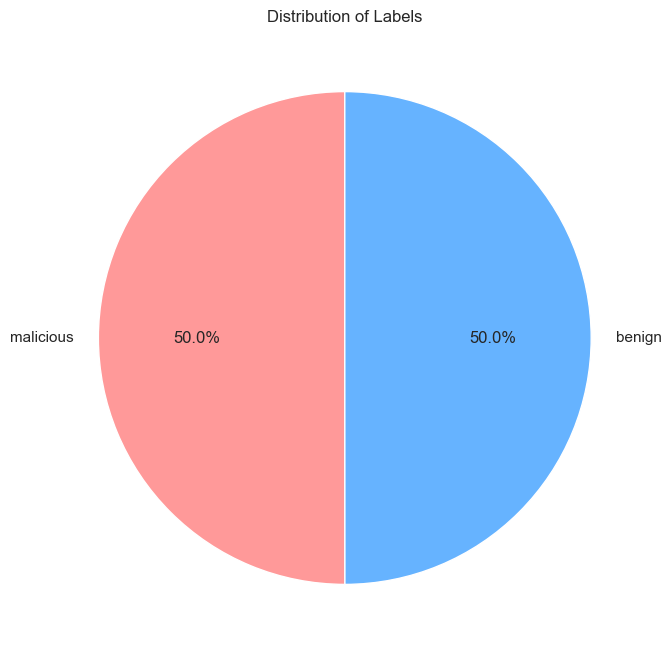


Total number of each label:
label
malicious    316561
benign       316450
Name: count, dtype: int64


In [22]:
import pandas as pd

# Set option to display full length of URLs and all rows
pd.set_option('display.max_colwidth', None)  # Menampilkan URL dengan panjang penuh
pd.set_option('display.max_rows', None)  # Menampilkan semua baris (hati-hati jika dataset besar)

# Display 100 random rows from the dataset
print("\nRandom rows of the dataset:")
print(data[['url', 'label', 'result']].sample(n=30).to_string(index=False))

# view piechart of the dataset and the distribution of the labels
plt.figure(figsize=(8, 8))
data['label'].value_counts().plot.pie(
    autopct='%1.1f%%', startangle=90, colors=['#ff9999', '#66b3ff'])
plt.title('Distribution of Labels')
plt.ylabel('')
plt.show()

# view total number of each label
print("\nTotal number of each label:")
print(data['label'].value_counts())



# ======================================
# 6. Visualizing Word Clouds
# ======================================

Generate word clouds for each class to visualize common patterns in URLs.

In [23]:
def plot_wordcloud(data_subset, title):
    """Plot a word cloud for a given subset of data."""
    combined_urls = " ".join(i for i in data_subset.url if isinstance(i, str))
    wordcloud = WordCloud(width=1600, height=800, colormap='Paired', background_color='black').generate(combined_urls)
    # plt.figure(figsize=(12, 14), facecolor='k')
    # plt.imshow(wordcloud, interpolation='bilinear')
    # plt.axis("off")
    # plt.title(title, color='white')
    # plt.tight_layout(pad=0)
    # plt.show()

# Plot wordclouds for each class
classes = data['label'].unique()
for cls in classes:
    subset = data[data.label == cls]
    # plot_wordcloud(subset, f"{cls.capitalize()} URLs Wordcloud")

# *This will display word clouds for each class (`benign`, `malicious`, etc.), highlighting the most frequent words in the URLs.*

# ======================================
# 7. Feature Engineering
# ======================================

Apply the previously defined feature engineering functions to extract features from the URLs.

In [24]:
from constant_datas import TRUSTED_TLDS
import pandas as pd
from urllib.parse import urlparse, parse_qs
import numpy as np

print("\nStarting feature engineering...")


# Apply feature engineering functions
data['secure_http'] = data['url'].apply(secure_http)  # 1
data['url_length'] = data['url'].apply(url_length)  # 2
data['is_long_subdomain'] = data['url'].apply(is_long_subdomain)  # 3
data['domain_entropy'] = data['url'].apply(domain_entropy)  # 4
data['protocol_count'] = data['url'].apply(protocol_count)  # 5
data['suspicious_path_words'] = data['url'].apply(suspicious_path_words)  # 6
data['tld_reputation'] = data['url'].apply(tld_reputation)  # 7
data['digit_letter_ratio'] = data['url'].apply(digit_letter_ratio)  # 8
data['special_char_count'] = data['url'].apply(special_char_count)  # 9
data['path_length'] = data['url'].apply(path_length)  # 10
data['contains_cyrillic'] = data['url'].apply(contains_cyrillic)  # 11
data['contains_at_symbol'] = data['url'].apply(contains_at_symbol)  # 12
data['subdomain_dot_count'] = data['url'].apply(subdomain_dot_count)  # 13
data['query_param_count'] = data['url'].apply(query_param_count)  # 14
data['path_zero_count'] = data['url'].apply(path_zero_count)  # 15
data['path_special_characters'] = data['url'].apply(
    path_special_characters)  # 16
data['domain_hyphen_count'] = data['url'].apply(domain_hyphen_count)  # 17
data['uppercase_lowercase_ratio'] = data['url'].apply(
    uppercase_lowercase_ratio)  # 18
data['domain_length'] = data['url'].apply(domain_length)  # 19
data['query_string_length'] = data['url'].apply(query_string_length)  # 20

# Add combination features
# 21. Kombinasi trusted TLD dan HTTPS
data['trusted_and_https'] = data['secure_http'] * data['tld_reputation']

# 22. Kombinasi domain entropy dan jumlah karakter spesial
data['entropy_special_char'] = data['domain_entropy'] * \
    data['special_char_count']

# 23. Kombinasi panjang URL dan subdomain panjang
data['long_url_long_subdomain'] = data['url_length'] * data['is_long_subdomain']

# 24. Kombinasi panjang path dan kata sensitif di path
data['path_sensitive_score'] = data['path_length'] * \
    data['suspicious_path_words']

# 25. Kombinasi rasio huruf besar/kecil dan jumlah karakter spesial
data['upper_lower_special_ratio'] = data['uppercase_lowercase_ratio'] * \
    data['special_char_count']

# 26. Kombinasi jumlah parameter query dan panjang query
data['query_complexity'] = data['query_param_count'] * \
    data['query_string_length']

# 27. Kombinasi domain entropy dan panjang domain
data['entropy_domain_length'] = data['domain_entropy'] * data['domain_length']

# 28. Kombinasi keamanan HTTPS dan jumlah karakter spesial di path
data['secure_path_score'] = data['secure_http'] * \
    data['path_special_characters']

# 29. Kombinasi reputasi TLD dan rasio huruf besar/kecil
data['tld_upper_ratio'] = data['tld_reputation'] * \
    data['uppercase_lowercase_ratio']


# append advanced features with combination features
# advanced_features += [
#     'trusted_and_https',
#     'entropy_special_char',
#     'long_url_long_subdomain',
#     'path_sensitive_score',
#     'upper_lower_special_ratio',
#     'query_complexity',
#     'entropy_domain_length',
#     'secure_path_score',
#     'tld_upper_ratio'
# ]

# Select Feature Columns
# Remove columns that are not present in the DataFrame
feature_columns = [col for col in advanced_features if col in data.columns]


# Select the relevant features for model training
X = data[feature_columns]
y = data['label']

print("\nFeature matrix X shape:", X.shape)
print("Target vector y distribution:")
print(y.value_counts())

# Print advanced features with numbering
print('\nAdvanced features:')
for i, feature in enumerate(advanced_features, 1):
    print(f"{i}. {feature}")

# print all columns
print("\nAll columns:")
print(data.columns)


Starting feature engineering...

Feature matrix X shape: (633011, 5)
Target vector y distribution:
label
malicious    316561
benign       316450
Name: count, dtype: int64

Advanced features:
1. secure_http
2. url_length
3. domain_entropy
4. contains_cyrillic
5. special_char_count

All columns:
Index(['url', 'label', 'result', 'secure_http', 'url_length',
       'is_long_subdomain', 'domain_entropy', 'protocol_count',
       'suspicious_path_words', 'tld_reputation', 'digit_letter_ratio',
       'special_char_count', 'path_length', 'contains_cyrillic',
       'contains_at_symbol', 'subdomain_dot_count', 'query_param_count',
       'path_zero_count', 'path_special_characters', 'domain_hyphen_count',
       'uppercase_lowercase_ratio', 'domain_length', 'query_string_length',
       'trusted_and_https', 'entropy_special_char', 'long_url_long_subdomain',
       'path_sensitive_score', 'upper_lower_special_ratio', 'query_complexity',
       'entropy_domain_length', 'secure_path_score', 'tld

# ======================================
# 8. Label Encoding
# ======================================

Encode the target labels into numerical values suitable for model training.

In [25]:
print("\nEncoding target labels...")

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
print("Classes found and their corresponding encoded labels:")
for idx, class_label in enumerate(label_encoder.classes_):
    print(f"{class_label}: {idx}")

# Save the label encoder for future use
dump(label_encoder, LABEL_ENCODER_PATH)
print(f"Label encoder saved to {LABEL_ENCODER_PATH}")


Encoding target labels...
Classes found and their corresponding encoded labels:
benign: 0
malicious: 1
Label encoder saved to ./models-balanced/label_encoder.pkl


# ======================================
# 9. Handling Missing Values for Categorical Features
# ======================================

Mengisi nilai null di fitur kategorikal sebelum melakukan encoding.

In [26]:
# Handling missing values
print("\nHandling missing values...")

# Fill missing values for numerical columns with the median
numerical_columns = X.select_dtypes(include=[np.number]).columns
X[numerical_columns] = X[numerical_columns].fillna(X[numerical_columns].median())

# Fill missing values for categorical columns with the mode
categorical_columns = X.select_dtypes(include=[object]).columns
if not categorical_columns.empty:
	X[categorical_columns] = X[categorical_columns].fillna(X[categorical_columns].mode().iloc[0])

print("Missing values handled successfully.")


Handling missing values...
Missing values handled successfully.


/var/folders/2t/4pk9n9cn4vq4vq2kybwvrbqc0000gn/T/ipykernel_24451/3675554555.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[numerical_columns] = X[numerical_columns].fillna(X[numerical_columns].median())


# ======================================
# 10. Encoding Categorical Features with TargetEncoder
# ======================================

Gunakan `TargetEncoder` untuk meng-encode fitur kategorikal.

In [27]:
from category_encoders import TargetEncoder
from sklearn.preprocessing import LabelEncoder
from joblib import dump

# Ensure the columns to be encoded are present in X
# cols_to_encode = ['trusted_and_https', 'entropy_special_char',
#                   'path_special_characters', 'subdomain_dot_count',
#                   'contains_cyrillic', 'domain_hyphen_count', "url_length", "special_char_count"]

# add all to cols_to_encode
cols_to_encode = advanced_features

# Add missing columns with default values
for col in cols_to_encode:
    if col not in X.columns:
        print(f"Adding missing column: {col}")
        X.loc[:, col] = 0  # Ensure addition is explicit using .loc

# Ensure there are no null values in columns to be encoded
for col in cols_to_encode:
    if X[col].isnull().any():
        print(f"Filling null values in column: {col}")
        X.loc[:, col] = X[col].fillna('missing')  # Explicitly fill nulls

# Ensure y is a pandas Series
if not isinstance(y, pd.Series):
    print("Converting y to pandas Series...")
    y = pd.Series(y, name='label')

# Convert y to numerical using LabelEncoder
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
print("Classes and their corresponding encoded labels:")
for class_label, encoded_label in zip(label_encoder.classes_, range(len(label_encoder.classes_))):
    print(f"{class_label}: {encoded_label}")

# Initialize TargetEncoder
encoder = TargetEncoder(cols=cols_to_encode)

# Fit encoder on training data
try:
    encoder.fit(X, y_encoded)
    print("TargetEncoder fitted successfully.")
except Exception as e:
    print(f"Error during encoder fitting: {e}")
    raise

# Transform training data
try:
    X_encoded = encoder.transform(X)
    print("TargetEncoder transformation successful.")
except Exception as e:
    print(f"Error during encoder transformation: {e}")
    raise

# Save the encoder and label encoder for future use
try:
    dump(encoder, ENCODER_PATH)
    dump(label_encoder, LABEL_ENCODER_PATH)
    print("Encoders saved successfully.")
except Exception as e:
    print(f"Error saving encoders: {e}")
    raise

# Debugging step: Preview transformed features
print("\nEncoding categorical features completed. Here's a preview of the encoded features:")
print(X_encoded.head())

Classes and their corresponding encoded labels:
benign: 0
malicious: 1
TargetEncoder fitted successfully.
TargetEncoder transformation successful.
Encoders saved successfully.

Encoding categorical features completed. Here's a preview of the encoded features:
   secure_http  url_length  domain_entropy  contains_cyrillic  \
0     0.059677    0.716993        0.703030           0.499901   
1     0.059677    0.534227        0.549515           0.499901   
2     0.059677    0.624215        0.549515           0.499901   
3     0.059677    0.419245        0.549515           0.499901   
4     0.059677    0.643480        0.549515           0.499901   

   special_char_count  
0            0.948780  
1            0.405704  
2            0.484534  
3            0.343458  
4            0.484534  


# ======================================
# 11. Cross-Validation with XGBoost
# ======================================

Perform k-fold cross-validation to evaluate the model's performance across different subsets of the data.


--- Fold 1 ---

Classification Report:
              precision    recall  f1-score   support

      benign       0.96      1.00      0.98     39524
   malicious       1.00      0.96      0.98     39603

    accuracy                           0.98     79127
   macro avg       0.98      0.98      0.98     79127
weighted avg       0.98      0.98      0.98     79127

Accuracy: 0.979
F1 Score: 0.979
ROC AUC Score: 0.992


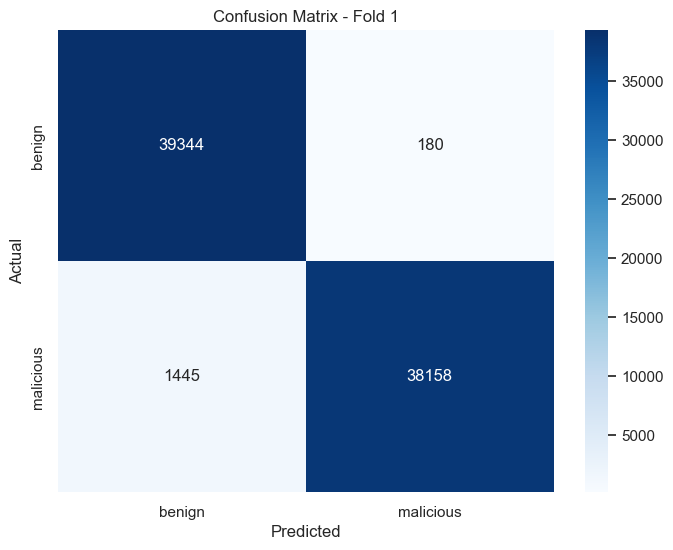

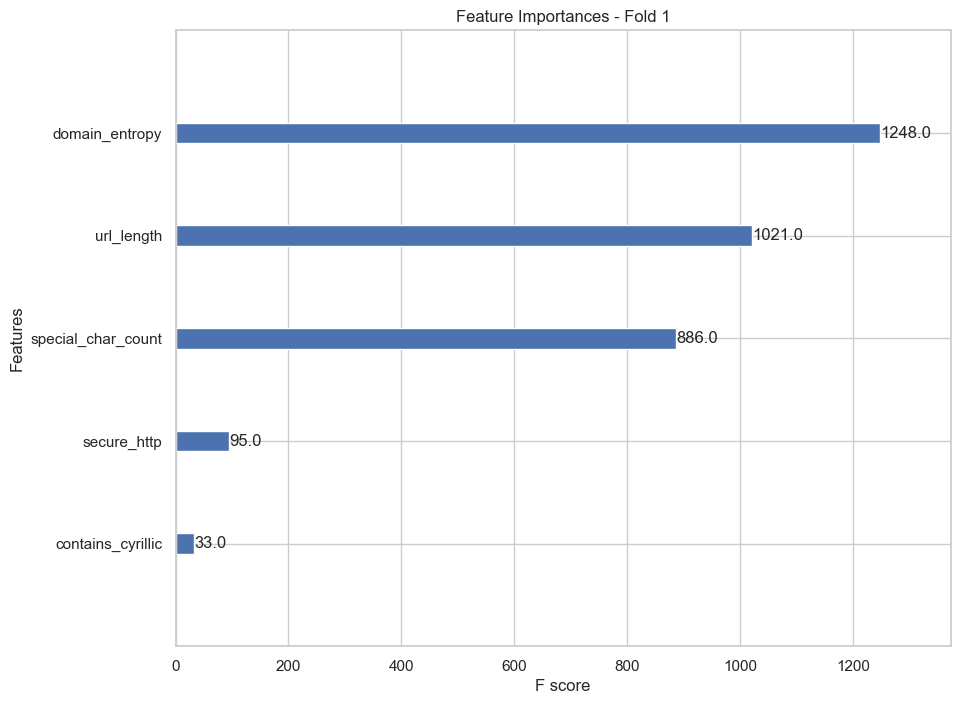


--- Fold 2 ---

Classification Report:
              precision    recall  f1-score   support

      benign       0.96      1.00      0.98     39404
   malicious       1.00      0.96      0.98     39723

    accuracy                           0.98     79127
   macro avg       0.98      0.98      0.98     79127
weighted avg       0.98      0.98      0.98     79127

Accuracy: 0.979
F1 Score: 0.979
ROC AUC Score: 0.992


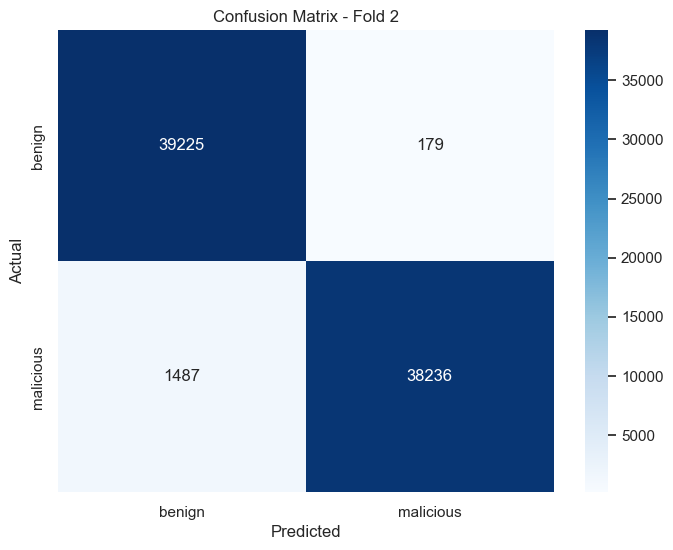

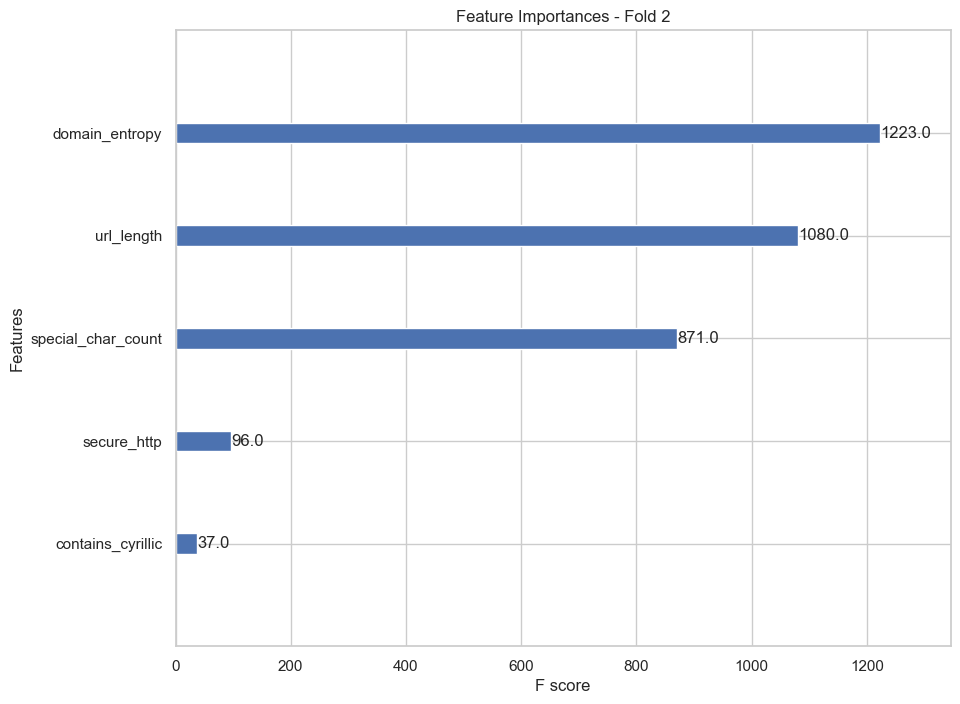


--- Fold 3 ---

Classification Report:
              precision    recall  f1-score   support

      benign       0.96      1.00      0.98     39461
   malicious       1.00      0.96      0.98     39666

    accuracy                           0.98     79127
   macro avg       0.98      0.98      0.98     79127
weighted avg       0.98      0.98      0.98     79127

Accuracy: 0.978
F1 Score: 0.978
ROC AUC Score: 0.991


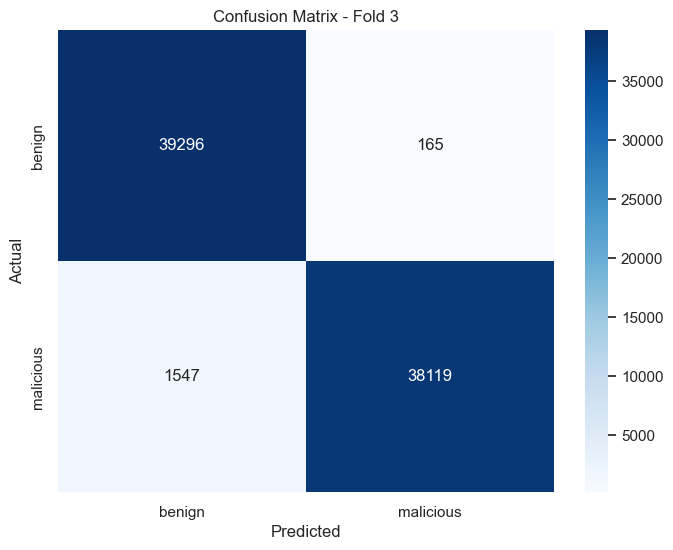

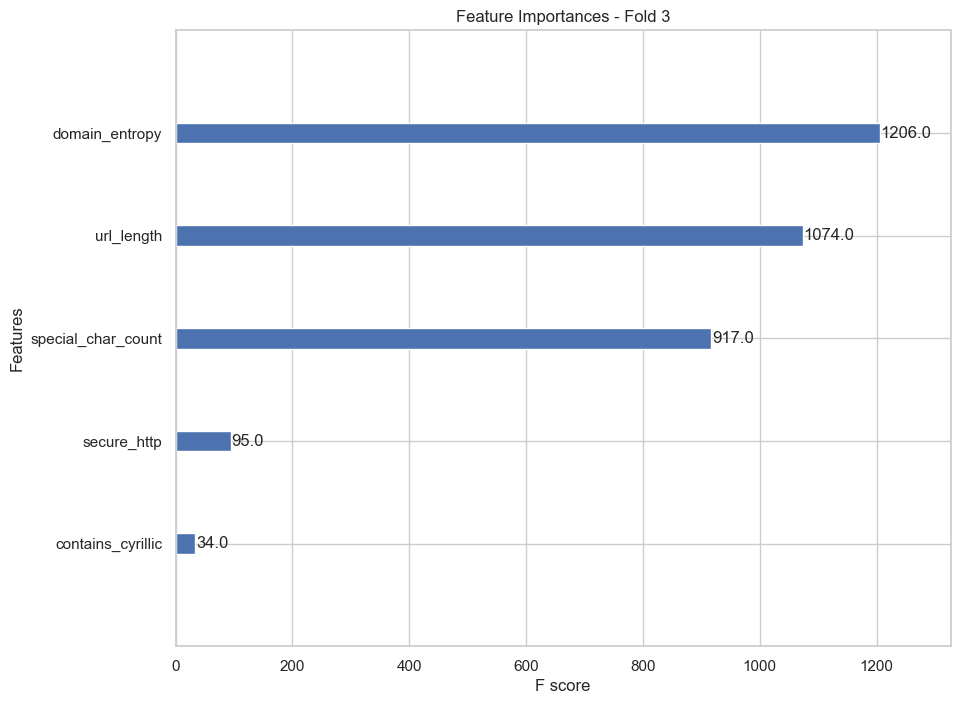


--- Fold 4 ---

Classification Report:
              precision    recall  f1-score   support

      benign       0.96      0.99      0.98     39429
   malicious       0.99      0.96      0.98     39697

    accuracy                           0.98     79126
   macro avg       0.98      0.98      0.98     79126
weighted avg       0.98      0.98      0.98     79126

Accuracy: 0.978
F1 Score: 0.978
ROC AUC Score: 0.991


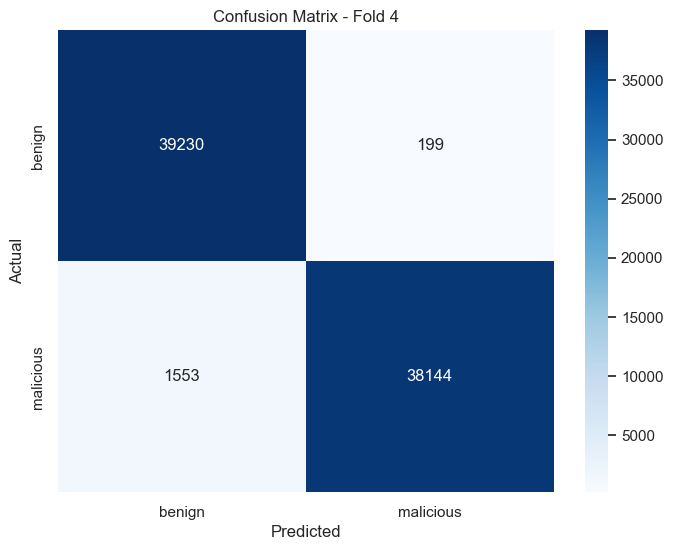

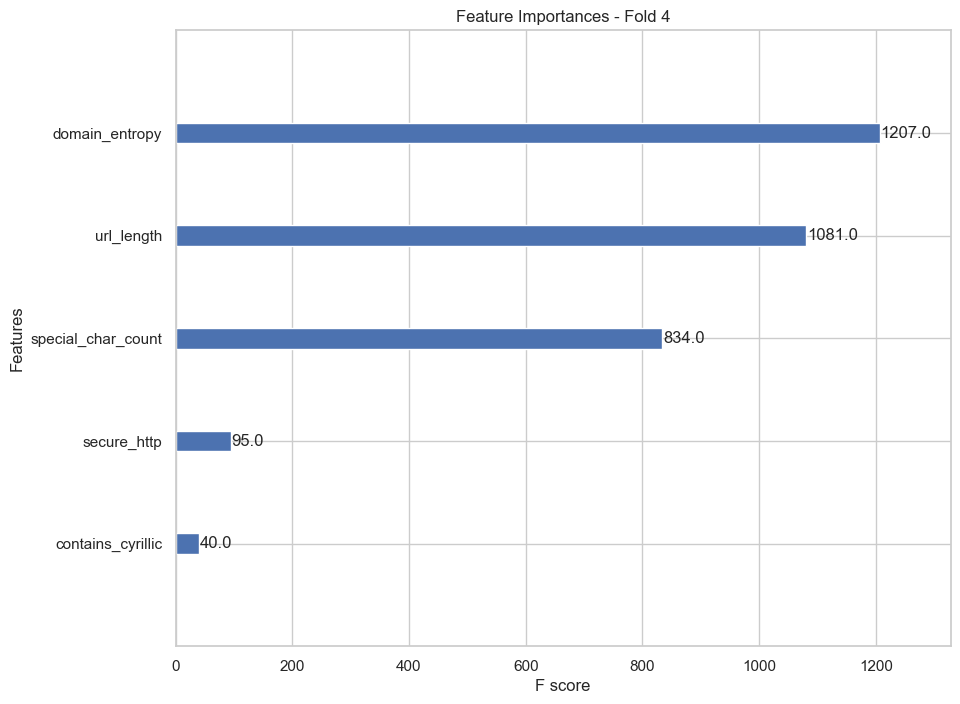


--- Fold 5 ---

Classification Report:
              precision    recall  f1-score   support

      benign       0.96      1.00      0.98     39824
   malicious       1.00      0.96      0.98     39302

    accuracy                           0.98     79126
   macro avg       0.98      0.98      0.98     79126
weighted avg       0.98      0.98      0.98     79126

Accuracy: 0.979
F1 Score: 0.979
ROC AUC Score: 0.991


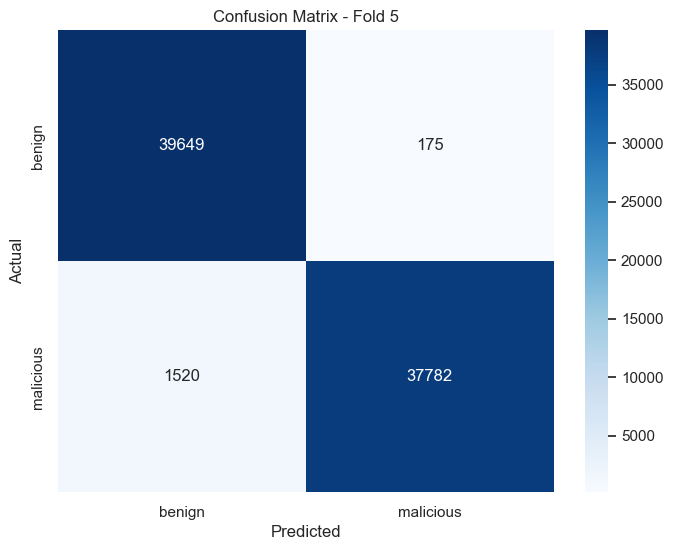

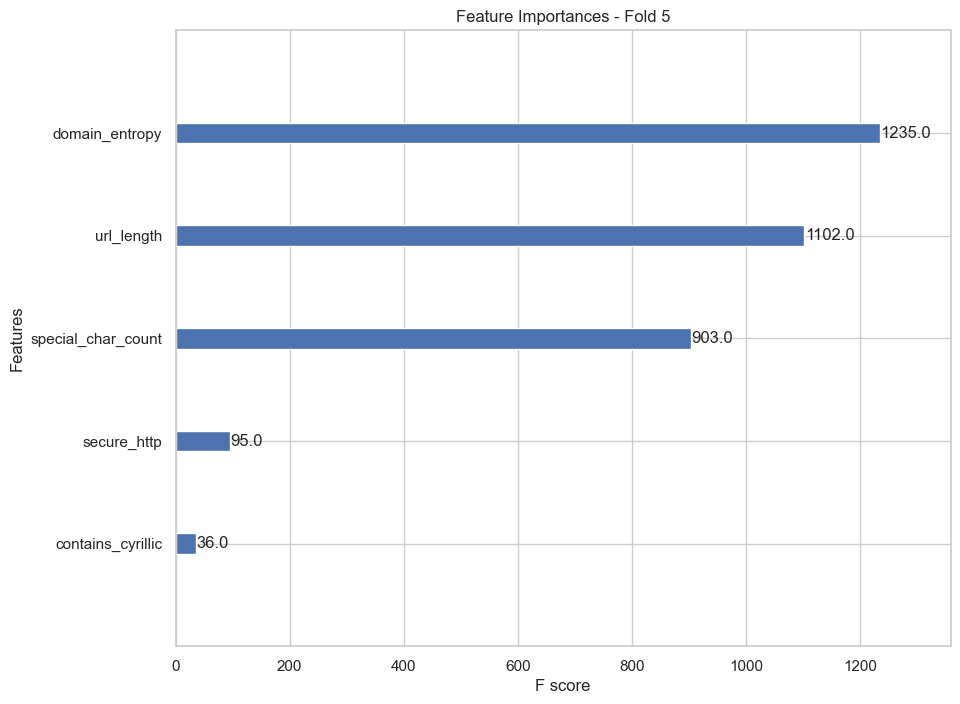


--- Fold 6 ---

Classification Report:
              precision    recall  f1-score   support

      benign       0.96      1.00      0.98     39418
   malicious       1.00      0.96      0.98     39708

    accuracy                           0.98     79126
   macro avg       0.98      0.98      0.98     79126
weighted avg       0.98      0.98      0.98     79126

Accuracy: 0.978
F1 Score: 0.978
ROC AUC Score: 0.991


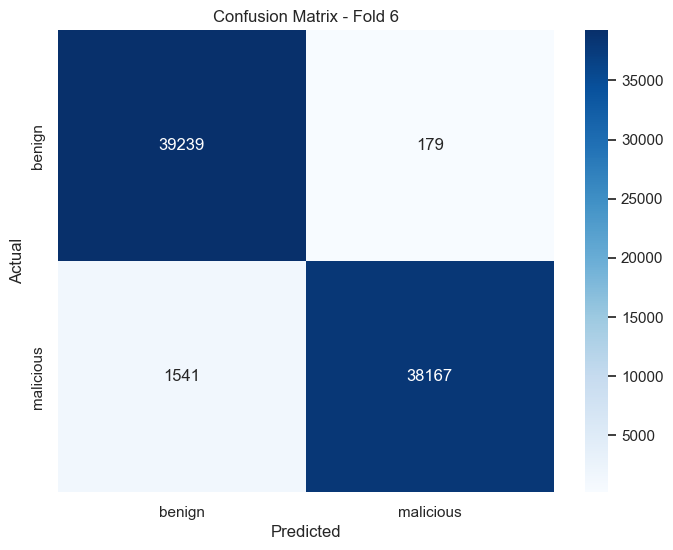

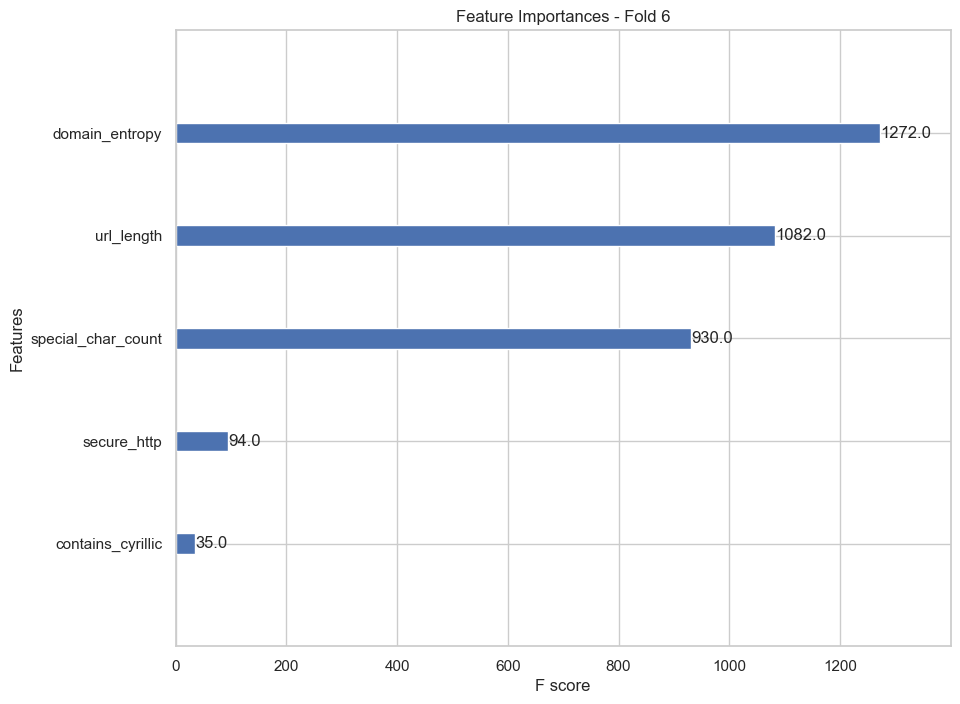


--- Fold 7 ---

Classification Report:
              precision    recall  f1-score   support

      benign       0.96      1.00      0.98     39734
   malicious       1.00      0.96      0.98     39392

    accuracy                           0.98     79126
   macro avg       0.98      0.98      0.98     79126
weighted avg       0.98      0.98      0.98     79126

Accuracy: 0.978
F1 Score: 0.978
ROC AUC Score: 0.991


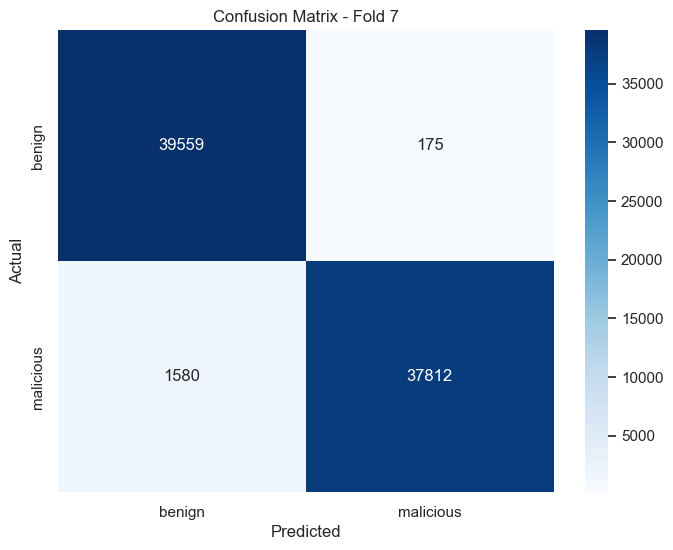

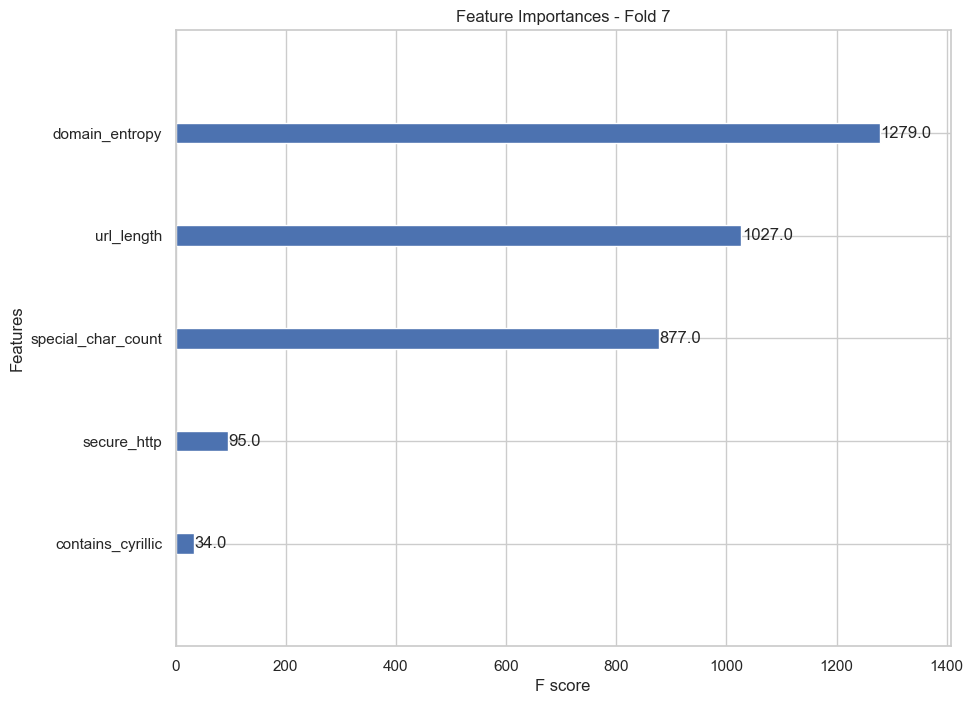


--- Fold 8 ---

Classification Report:
              precision    recall  f1-score   support

      benign       0.96      1.00      0.98     39656
   malicious       1.00      0.96      0.98     39470

    accuracy                           0.98     79126
   macro avg       0.98      0.98      0.98     79126
weighted avg       0.98      0.98      0.98     79126

Accuracy: 0.979
F1 Score: 0.979
ROC AUC Score: 0.991


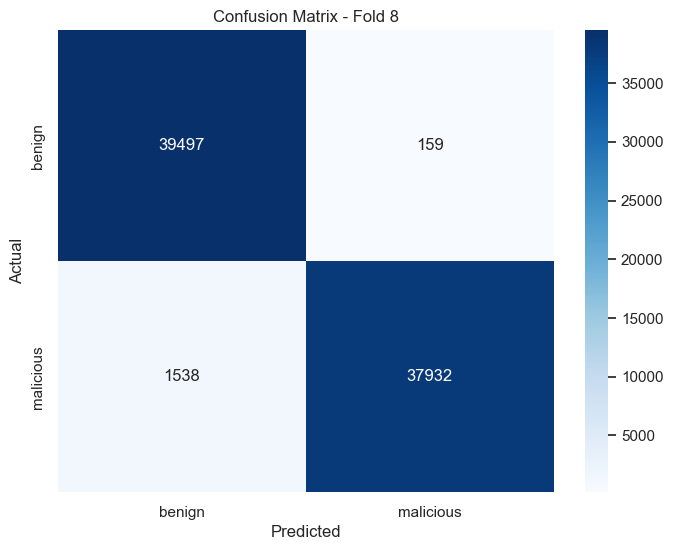

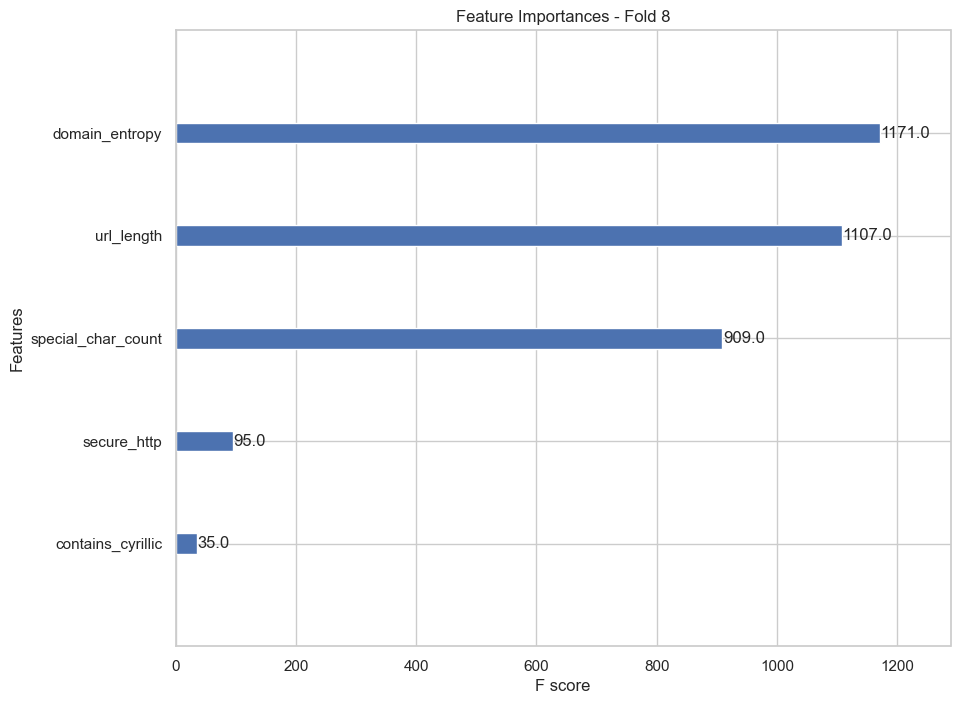


--- Overall Metrics ---
Mean Accuracy: 0.978
Mean F1 Score: 0.978
Mean ROC AUC Score: 0.991

--- Results from every fold ---
Fold 1: Accuracy=0.979, F1 Score=0.979, ROC AUC=0.992
Fold 2: Accuracy=0.979, F1 Score=0.979, ROC AUC=0.992
Fold 3: Accuracy=0.978, F1 Score=0.978, ROC AUC=0.991
Fold 4: Accuracy=0.978, F1 Score=0.978, ROC AUC=0.991
Fold 5: Accuracy=0.979, F1 Score=0.979, ROC AUC=0.991
Fold 6: Accuracy=0.978, F1 Score=0.978, ROC AUC=0.991
Fold 7: Accuracy=0.978, F1 Score=0.978, ROC AUC=0.991
Fold 8: Accuracy=0.979, F1 Score=0.979, ROC AUC=0.991


In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import KFold
from xgboost import XGBClassifier, plot_importance
from sklearn import metrics
from category_encoders import TargetEncoder
from sklearn.preprocessing import LabelEncoder

# Initialize TargetEncoder
encoder = TargetEncoder(cols=cols_to_encode)

# Fit encoder on training data
encoder.fit(X, y_encoded)

# Transform training data
X_encoded = encoder.transform(X)

# Initialize label encoder for target (assuming y_encoded is already encoded)
label_encoder = LabelEncoder()
# Ensure it's encoded before training
y_encoded = label_encoder.fit_transform(y)

# Ensure y_encoded is a 1D array
y_encoded = y_encoded.ravel()

# Initialize k-fold cross-validator
num_folds = 8
kf = KFold(n_splits=num_folds, shuffle=True, random_state=42)

# Lists to store metrics
accuracy_scores = []
confusion_matrices = []
f1_scores = []
roc_auc_scores = []
feature_importances_list = []

fold_number = 1

for train_index, test_index in kf.split(X_encoded, y_encoded):
    print(f"\n--- Fold {fold_number} ---")

    X_train_fold, X_test_fold = X_encoded.iloc[train_index], X_encoded.iloc[test_index]
    y_train_fold, y_test_fold = y_encoded[train_index], y_encoded[test_index]

    # Ensure y_train_fold and y_test_fold are 1D arrays
    y_train_fold = np.ravel(y_train_fold)
    y_test_fold = np.ravel(y_test_fold)

    # Initialize XGBoost Classifier
    xgb_model = XGBClassifier(
        n_estimators=100,  # Tuning n_estimators
        learning_rate=0.1,  # Tuning learning_rate
        max_depth=6,  # Tuning max_depth
        random_state=42,
        eval_metric='mlogloss',
        n_jobs=-1
    )

    # Train the model
    xgb_model.fit(X_train_fold, y_train_fold)

    # Predict on test fold
    y_pred_xgb = xgb_model.predict(X_test_fold)

    # Confusion Matrix
    cm_fold = metrics.confusion_matrix(
        y_test_fold, y_pred_xgb, labels=np.arange(len(label_encoder.classes_)))
    confusion_matrices.append(cm_fold)

    # Classification Report
    print("\nClassification Report:")
    print(metrics.classification_report(y_test_fold,
          y_pred_xgb, target_names=label_encoder.classes_))

    # Accuracy Score
    score = metrics.accuracy_score(y_test_fold, y_pred_xgb)
    print(f"Accuracy: {score:.3f}")
    accuracy_scores.append(score)

    # F1 Score
    f1_score_fold = metrics.f1_score(
        y_test_fold, y_pred_xgb, average='weighted')
    print(f"F1 Score: {f1_score_fold:.3f}")
    f1_scores.append(f1_score_fold)

    # ROC AUC Score (for multi-class classification)
    probs = xgb_model.predict_proba(X_test_fold)

    # Compute ROC AUC Score for multi-class classification
    if len(label_encoder.classes_) > 2:  # Multi-class scenario
        roc_auc_score_fold = metrics.roc_auc_score(
            y_test_fold, probs, multi_class='ovr')
    else:  # Binary classification
        roc_auc_score_fold = metrics.roc_auc_score(y_test_fold, probs[:, 1])

    print(f"ROC AUC Score: {roc_auc_score_fold:.3f}")
    roc_auc_scores.append(roc_auc_score_fold)

    # Confusion Matrix Heatmap
    cm_df_fold = pd.DataFrame(cm_fold, index=label_encoder.classes_,
                              columns=label_encoder.classes_)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm_df_fold, annot=True, fmt="d", cmap='Blues')
    plt.title(f'Confusion Matrix - Fold {fold_number}')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()

    # Feature Importances using XGBoost's plot_importance
    fig, ax = plt.subplots(figsize=(10, 8))
    plot_importance(xgb_model, importance_type='weight',
                    max_num_features=50, ax=ax)
    plt.title(f'Feature Importances - Fold {fold_number}')
    plt.show()

    # Save feature importances for this fold with importance_type='weight'
    booster = xgb_model.get_booster()
    importance_dict = booster.get_score(importance_type='weight')
    features = list(importance_dict.keys())
    importances = list(importance_dict.values())

    # Ensure the lengths of features and importances are the same
    if len(features) == len(importances):
        feature_importances_df = pd.DataFrame({
            'feature': features,
            'importance': importances
        }).sort_values(by='importance', ascending=False)
    else:
        print("Error: Mismatch in lengths of features and importances")
    # Append to the list of feature importances
    feature_importances_list.append(feature_importances_df)

    fold_number += 1


# summarize the results of every fold
print("\n--- Overall Metrics ---")
print(f"Mean Accuracy: {np.mean(accuracy_scores):.3f}")
print(f"Mean F1 Score: {np.mean(f1_scores):.3f}")
print(f"Mean ROC AUC Score: {np.mean(roc_auc_scores):.3f}")

# print table of result from every fold
print("\n--- Results from every fold ---")
for i, (acc, f1, roc_auc) in enumerate(zip(accuracy_scores, f1_scores, roc_auc_scores), 1):
    print(
        f"Fold {i}: Accuracy={acc:.3f}, F1 Score={f1:.3f}, ROC AUC={roc_auc:.3f}")

# ======================================
# 12. Summary of Cross-Validation Metrics
# ======================================

Calculate and visualize the average accuracy and feature importances across all folds.


--- Summarized Feature Importances ---
1. domain_entropy: 1230.125
2. url_length: 1071.750
3. special_char_count: 890.875
4. secure_http: 95.000
5. contains_cyrillic: 35.500


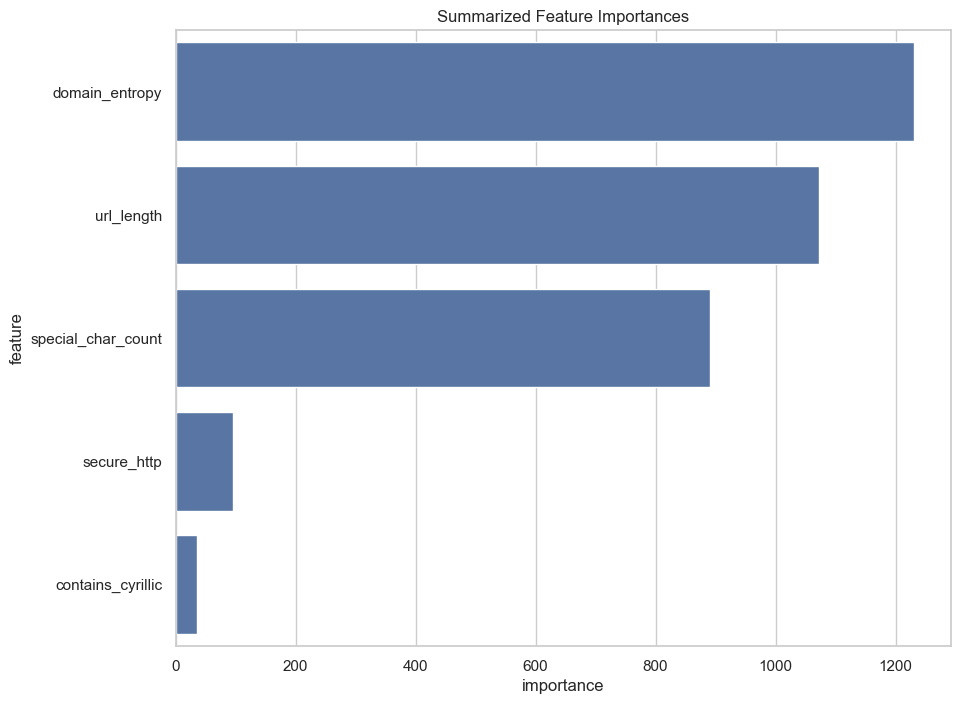


--- Final Results ---
Average Accuracy: 0.978
Average F1 Score: 0.978
Average ROC AUC Score: 0.991


In [29]:
# Summarize feature importances across all folds
all_feature_importances = pd.concat(feature_importances_list, axis=0)
mean_feature_importances = all_feature_importances.groupby('feature').mean().sort_values(by='importance', ascending=False)

# Print summarized feature importances
print("\n--- Summarized Feature Importances ---")
for i, (feature, importance) in enumerate(mean_feature_importances.itertuples(), 1):
  print(f"{i}. {feature}: {importance:.3f}")

# Plot summarized feature importances
plt.figure(figsize=(10, 8))
sns.barplot(x='importance', y='feature', data=mean_feature_importances.reset_index())
plt.title('Summarized Feature Importances')
plt.show()

# Print average scores across all folds
print("\n--- Final Results ---")
print(f"Average Accuracy: {np.mean(accuracy_scores):.3f}")
print(f"Average F1 Score: {np.mean(f1_scores):.3f}")
print(f"Average ROC AUC Score: {np.mean(roc_auc_scores):.3f}")

# ======================================
# 13. Training the Final Model
# ======================================

Train the final XGBoost model on the entire dataset after balancing it with oversampling.

In [30]:
from sklearn.model_selection import GridSearchCV, train_test_split, cross_val_score
import matplotlib.pyplot as plt
from xgboost import XGBClassifier, plot_importance
import seaborn as sns
from sklearn import metrics
from joblib import dump

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y_encoded, test_size=0.2, random_state=42)


# param_grid = {
#     'n_estimators': [100, 150],
#     'max_depth': [4, 6],
#     'learning_rate': [0.01, 0.1],
#     'gamma': [1],
#     'subsample': [0.8],
#     'colsample_bytree': [0.8],
#     'min_child_weight': [1, 2]
# }

# # create paramgrid for complex model
# param_grid_complex ={
#     'n_estimators': [100, 150],
#     'max_depth': [6, 8],
#     'learning_rate': [0.05, 0.1],
#     'gamma': [0, 1],
# }

# Define parameter grid for GridSearchCV
param_grid = {
    'n_estimators': [100, 150],              # Jumlah estimators 
    'max_depth': [8, 10],                     # Max depth 
    'learning_rate': [0.05, 0.1],             # Learning rate yang terbukti efektif
    'gamma': [0,  1],                          # Gamma 
    'subsample': [0.7],                       # Subsample 
    'colsample_bytree': [1],                  # Colsample_bytree 
    'min_child_weight': [1],                   # Min child weight 
    'max_delta_step': [0],                     # Tidak ada perubahan pada max_delta_step
    'scale_pos_weight': [1],                   # Scale_pos_weight yang terbukti baik
    'tree_method': ['auto'],                  # Tree method 
    'eval_metric': ['logloss']                # Evaluasi menggunakan logloss
}

# Initialize base XGBoost model
base_xgb = XGBClassifier(random_state=42, n_jobs=-1)

# Perform grid search for hyperparameter tuning
grid_search = GridSearchCV(
    estimator=base_xgb,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=2
)

print("\nPerforming GridSearchCV...")
grid_search.fit(X_train, y_train)

# Output best parameters and score
print("\nBest parameters found:")
print(grid_search.best_params_)
print(f"\nBest cross-validation score: {grid_search.best_score_:.3f}")

# Train the final model using the best parameters
final_xgb = grid_search.best_estimator_
final_xgb.fit(X_train, y_train)

# Save the final model to disk using dump
dump(final_xgb, MODEL_PATH)
print("Final model saved as 'final_xgb_model.pkl'")


Performing GridSearchCV...
Fitting 5 folds for each of 16 candidates, totalling 80 fits
[CV] END colsample_bytree=1, eval_metric=logloss, gamma=0, learning_rate=0.05, max_delta_step=0, max_depth=8, min_child_weight=1, n_estimators=100, scale_pos_weight=1, subsample=0.7, tree_method=auto; total time=   2.4s
[CV] END colsample_bytree=1, eval_metric=logloss, gamma=0, learning_rate=0.05, max_delta_step=0, max_depth=8, min_child_weight=1, n_estimators=100, scale_pos_weight=1, subsample=0.7, tree_method=auto; total time=   2.4s
[CV] END colsample_bytree=1, eval_metric=logloss, gamma=0, learning_rate=0.05, max_delta_step=0, max_depth=8, min_child_weight=1, n_estimators=100, scale_pos_weight=1, subsample=0.7, tree_method=auto; total time=   2.4s
[CV] END colsample_bytree=1, eval_metric=logloss, gamma=0, learning_rate=0.05, max_delta_step=0, max_depth=8, min_child_weight=1, n_estimators=100, scale_pos_weight=1, subsample=0.7, tree_method=auto; total time=   2.5s
[CV] END colsample_bytree=1, ev

<Figure size 1000x600 with 0 Axes>

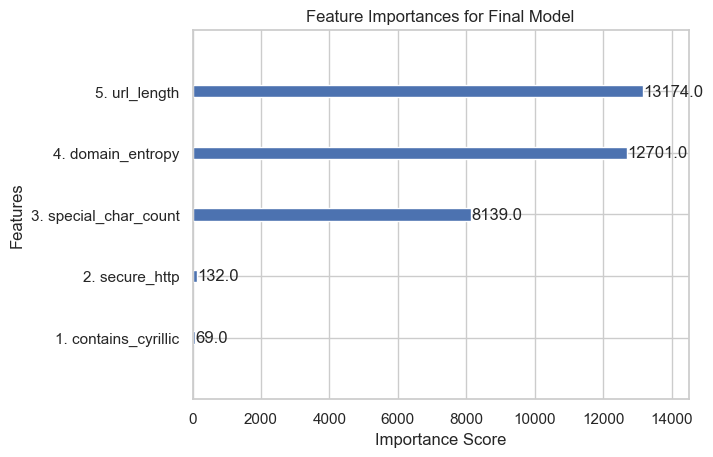


Training Set Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98    253326
           1       1.00      0.97      0.98    253082

    accuracy                           0.98    506408
   macro avg       0.98      0.98      0.98    506408
weighted avg       0.98      0.98      0.98    506408


Test Set Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     63124
           1       0.99      0.97      0.98     63479

    accuracy                           0.98    126603
   macro avg       0.98      0.98      0.98    126603
weighted avg       0.98      0.98      0.98    126603



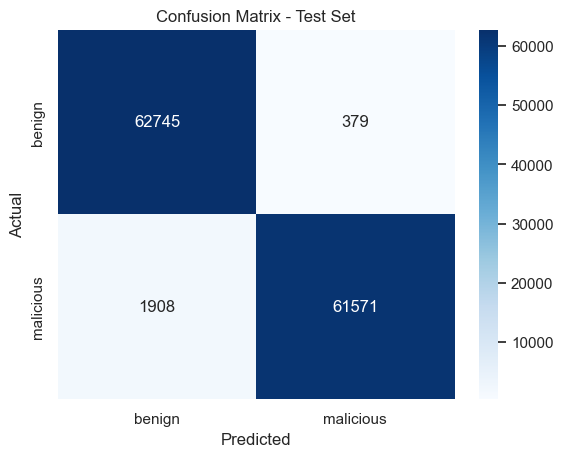


Cross-Validation Accuracy: 0.97 ± 0.04


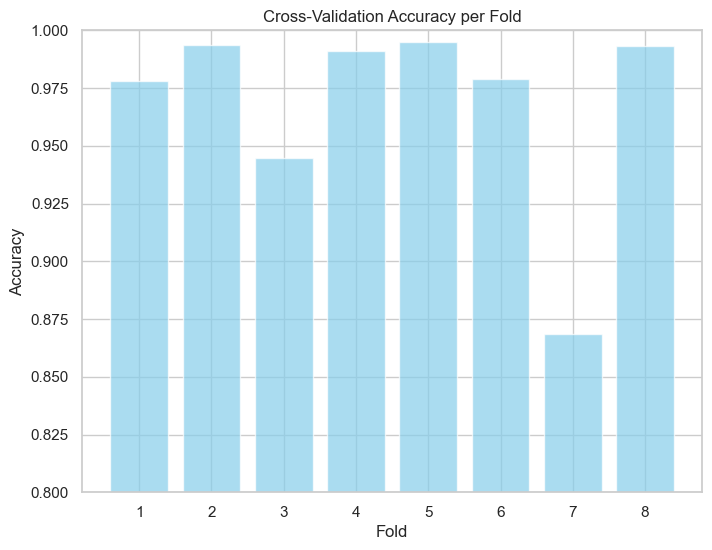

In [31]:
# Feature Importances for Final Model
print('=================================')
plt.figure(figsize=(10, 6))
plot_importance(final_xgb, importance_type='weight', max_num_features=40)
plt.title('Feature Importances for Final Model')
plt.xlabel('Importance Score')
plt.ylabel('Features')

# Add numbering to features
ax = plt.gca()
labels = [item.get_text() for item in ax.get_yticklabels()]
ax.set_yticklabels([f"{i+1}. {label}" for i, label in enumerate(labels)])

plt.show()

# Evaluate the final model on training set
y_train_pred = final_xgb.predict(X_train)
print("\nTraining Set Classification Report:")
print(metrics.classification_report(y_train, y_train_pred))

# Evaluate the final model on test set
y_test_pred = final_xgb.predict(X_test)
print("\nTest Set Classification Report:")
print(metrics.classification_report(y_test, y_test_pred))

# Confusion Matrix for Test Set
cm_test = metrics.confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title("Confusion Matrix - Test Set")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Perform cross-validation to check consistency
cv_scores = cross_val_score(final_xgb, X_encoded, y_encoded, cv=8, scoring='accuracy')
print(f"\nCross-Validation Accuracy: {cv_scores.mean():.2f} ± {cv_scores.std():.2f}")
plt.figure(figsize=(8, 6))
plt.bar(range(1, len(cv_scores) + 1), cv_scores, color='skyblue', alpha=0.7)
plt.title('Cross-Validation Accuracy per Fold')
plt.xlabel('Fold')
plt.ylabel('Accuracy')
plt.ylim(0.8, 1.0)
plt.show()

# ROC Curve for Training and Test Sets
from sklearn.metrics import roc_curve, roc_auc_score

# Training set
y_train_proba = final_xgb.predict_proba(X_train)[:, 1]
fpr_train, tpr_train, _ = roc_curve(y_train, y_train_proba)
auc_train = roc_auc_score(y_train, y_train_proba)

# Test set
y_test_proba = final_xgb.predict_proba(X_test)[:, 1]
fpr_test, tpr_test, _ = roc_curve(y_test, y_test_proba)
auc_test = roc_auc_score(y_test, y_test_proba)

# Plot ROC Curves
# plt.figure(figsize=(8, 6))
# plt.plot(fpr_train, tpr_train, label=f"Training Set AUC = {auc_train:.2f}")
# plt.plot(fpr_test, tpr_test, label=f"Test Set AUC = {auc_test:.2f}", linestyle='--')
# plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
# plt.xlabel("False Positive Rate")
# plt.ylabel("True Positive Rate")
# plt.title("ROC Curve (Training vs Test)")
# plt.legend()
# plt.show()


# ======================================
# 14. Predicting on Test URLs
# ======================================

Prepare a set of test URLs, apply feature engineering, and use the trained model to predict their classifications.

In [32]:
from IPython.display import display
import joblib
import pandas as pd
from joblib import dump

print("\nStarting feature engineering on test data...")

# Prepare test URLs
test_urls = [
    'https://www.google.com/info',
    'https://www.facebook.com',
    'https://www.amazon.com',
    'https://www.netflix.com',
    'https://www.reddit.com',
    'https://www.youtube.com/',
    'https://www.twitter.com',
    'https://www.linkedin.com',
    'https://www.instagram.com',
    'https://www.microsoft.com',
    'https://www.apple.com',
    'https://www.github.com',
    'https://www.wikipedia.org',
    'https://www.quora.com',
    'https://www.pinterest.com',
    'https://www.ebay.com',
    'https://www.dropbox.com',
    'https://www.paypal.com',
    'https://www.salesforce.com',
    'https://www.tesla.com',
    "allmusic.com/album/crazy-from-the-heat-r16990",
    "http://peluqueriadeautor.com/index.php?option=com_virtuemart&page=shop.browse&category_id=31&Itemid=70",
    "http://9779.info/%E5%84%BF%E7%AB%A5%E7%AB%8B%E4%BD",
    "http://9779.info/%E5%84%BF%E7%AB%A5%E7%AB%8B%E4%BD",
    "http://alexpay2.beget.tech",
    'http://www.pn-wuppertal.de/links/2-linkseite/5-httpwwwkrebshilfede',
    "https://spada.upnyk.ac.id/login/index.php",
    "https://spada.upnyk.ac.id/",
    "https://bima.upnyk.ac.id/",
    "https://bankindonesia.co.id/",  # Indonesian bank website
    "https://bаnkindonesiа.co.id/",  # Phishing URL with cyrillic 'a'
    "https://www.bi.go.id/id/",
    "https://www.bі.go.іԁ/іԁ/"
]

# Convert URLs to DataFrame
test_data = pd.DataFrame({'url': test_urls})

# Apply feature engineering functions
test_data['secure_http'] = test_data['url'].apply(secure_http)
test_data['url_length'] = test_data['url'].apply(url_length)
test_data['is_long_subdomain'] = test_data['url'].apply(is_long_subdomain)
test_data['domain_entropy'] = test_data['url'].apply(domain_entropy)
test_data['protocol_count'] = test_data['url'].apply(protocol_count)
test_data['suspicious_path_words'] = test_data['url'].apply(
    suspicious_path_words)
test_data['tld_reputation'] = test_data['url'].apply(tld_reputation)
test_data['digit_letter_ratio'] = test_data['url'].apply(digit_letter_ratio)
test_data['special_char_count'] = test_data['url'].apply(special_char_count)
test_data['path_length'] = test_data['url'].apply(path_length)
test_data['contains_cyrillic'] = test_data['url'].apply(contains_cyrillic)
test_data['contains_at_symbol'] = test_data['url'].apply(contains_at_symbol)
test_data['subdomain_dot_count'] = test_data['url'].apply(subdomain_dot_count)
test_data['query_param_count'] = test_data['url'].apply(query_param_count)
test_data['path_zero_count'] = test_data['url'].apply(path_zero_count)
test_data['path_special_characters'] = test_data['url'].apply(
    path_special_characters)
test_data['domain_hyphen_count'] = test_data['url'].apply(domain_hyphen_count)
test_data['uppercase_lowercase_ratio'] = test_data['url'].apply(
    uppercase_lowercase_ratio)
test_data['domain_length'] = test_data['url'].apply(domain_length)
test_data['query_string_length'] = test_data['url'].apply(query_string_length)
# test_data['sus']


# Add combination features
# 21. Kombinasi trusted TLD dan HTTPS
test_data['trusted_and_https'] = test_data['secure_http'] * \
    test_data['tld_reputation']

# 22. Kombinasi domain entropy dan jumlah karakter spesial
test_data['entropy_special_char'] = test_data['domain_entropy'] * \
    test_data['special_char_count']

# 23. Kombinasi panjang URL dan subdomain panjang
test_data['long_url_long_subdomain'] = test_data['url_length'] * \
    test_data['is_long_subdomain']

# 24. Kombinasi panjang path dan kata sensitif di path
test_data['path_sensitive_score'] = test_data['path_length'] * \
    test_data['suspicious_path_words']

# 25. Kombinasi rasio huruf besar/kecil dan jumlah karakter spesial
test_data['upper_lower_special_ratio'] = test_data['uppercase_lowercase_ratio'] * \
    test_data['special_char_count']

# 26. Kombinasi jumlah parameter query dan panjang query
test_data['query_complexity'] = test_data['query_param_count'] * \
    test_data['query_string_length']

# 27. Kombinasi domain entropy dan panjang domain
test_data['entropy_domain_length'] = test_data['domain_entropy'] * \
    test_data['domain_length']

# 28. Kombinasi keamanan HTTPS dan jumlah karakter spesial di path
test_data['secure_path_score'] = test_data['secure_http'] * \
    test_data['path_special_characters']

# 29. Kombinasi reputasi TLD dan rasio huruf besar/kecil
test_data['tld_upper_ratio'] = test_data['tld_reputation'] * \
    test_data['uppercase_lowercase_ratio']

# Select Feature Columns
feature_columns = advanced_features

# Select features
test_features = test_data[feature_columns]

# Handling missing values
print("\nHandling missing values...")

# Load TargetEncoder and XGBoost model
try:
    encoder_loaded = joblib.load(ENCODER_PATH)
    label_encoder_loaded = joblib.load(LABEL_ENCODER_PATH)
    final_xgb_loaded = joblib.load(MODEL_PATH)
    print("Encoders and model loaded successfully.")
except FileNotFoundError as e:
    print(f"Error: {e}. Ensure the encoder and model files exist.")
    exit(1)
except Exception as e:
    print(f"An error occurred while loading encoders and model: {e}")
    exit(1)

# Align test features with training features
expected_feature_columns = encoder_loaded.get_feature_names_out()
missing_cols = set(expected_feature_columns) - set(test_features.columns)
for col in missing_cols:
    print(f"Adding missing column: {col}")
    test_features[col] = 0  # Default value for missing features

extra_cols = set(test_features.columns) - set(expected_feature_columns)
if extra_cols:
    print(f"Removing unexpected columns: {extra_cols}")
    test_features = test_features.drop(columns=extra_cols)

# Reorder columns to match the model's training data
test_features = test_features[expected_feature_columns]

# Transform test data using loaded encoder
X_test_encoded = encoder_loaded.transform(test_features)

print("\nFeature engineering on test data completed. Here's a preview:")
print(X_test_encoded.head())

# Predict using the loaded model
test_predictions_encoded = final_xgb_loaded.predict(X_test_encoded)

# Decode predictions to original labels
test_predictions = label_encoder_loaded.inverse_transform(
    test_predictions_encoded)

# Display predictions
test_data['Predicted_Type'] = test_predictions
print("\nTest URL Predictions:")
display(test_data[['url', 'Predicted_Type']])


Starting feature engineering on test data...

Handling missing values...
Encoders and model loaded successfully.

Feature engineering on test data completed. Here's a preview:
   secure_http  url_length  domain_entropy  contains_cyrillic  \
0     0.059677    0.612618        0.703030           0.499901   
1     0.059677    0.643669        0.346193           0.499901   
2     0.059677    0.716993        0.355909           0.499901   
3     0.059677    0.675014        0.405850           0.499901   
4     0.059677    0.716993        0.355909           0.499901   

   special_char_count  
0            0.418562  
1            0.948780  
2            0.948780  
3            0.948780  
4            0.948780  

Test URL Predictions:


,url,Predicted_Type
0,https://www.google.com/info,malicious
1,https://www.facebook.com,benign
2,https://www.amazon.com,benign
3,https://www.netflix.com,benign
4,https://www.reddit.com,benign
5,https://www.youtube.com/,benign
6,https://www.twitter.com,benign
7,https://www.linkedin.com,benign
8,https://www.instagram.com,benign
9,https://www.microsoft.com,benign
